In [1]:
import os, re
import pandas as pd
import seaborn as sns
from tqdm import tqdm
from matplotlib.ticker import FuncFormatter

/home/bertolo/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/bertolo/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


# Imports and data preparation

In [2]:
img_fldr = '../images/'

DATA_dir = 'tata_n5000_min20_max100'

Dir2Lbl_cnvtb = {
    'Toxins_mxd':'tox',
    'miRNA': 'mrna',
    'AMR': 'amr',
    'tata_n5000_min20_max100': 'tata',
    'tata_n5000_min1000_max3000': 'tata'
}

Dir2Meta_cnvtb = {
    'Toxins_mxd':'toxinmix',
    'miRNA': 'mrna',
    'AMR': 'amr',
    'tata_n5000_min20_max100': 'tata_n5000_min20_max100',
    'tata_n5000_min1000_max3000': 'tata_n5000_min1000_max3000'
}

Dir2Title_cnvtb = {
    'Toxins_mxd':'Toxins (mix)',
    'miRNA': 'miRNA',
    'AMR': 'AMR',
    'tata_n5000_min20_max100': 'TATA Box 20-100',
    'tata_n5000_min1000_max3000': 'TATA Box 1k-3k'
}

results_dir = f'results_ppl_{DATA_dir}/'

metrics_rows     = []
predictions_rows = []

save_dfs = False
save_fig = True

In [3]:
test_metadata = pd.read_csv(f'data/{Dir2Meta_cnvtb[DATA_dir]}_test_metadata.tsv', sep='\t')
train_metadata = pd.read_csv(f'data/{Dir2Meta_cnvtb[DATA_dir]}_train_metadata.tsv', sep='\t')

test_metadata['split'] = ['Test'] * len(test_metadata)
train_metadata['split'] = ['Train'] * len(train_metadata)

metadata_df = pd.concat([test_metadata, train_metadata]).reset_index(drop=True)

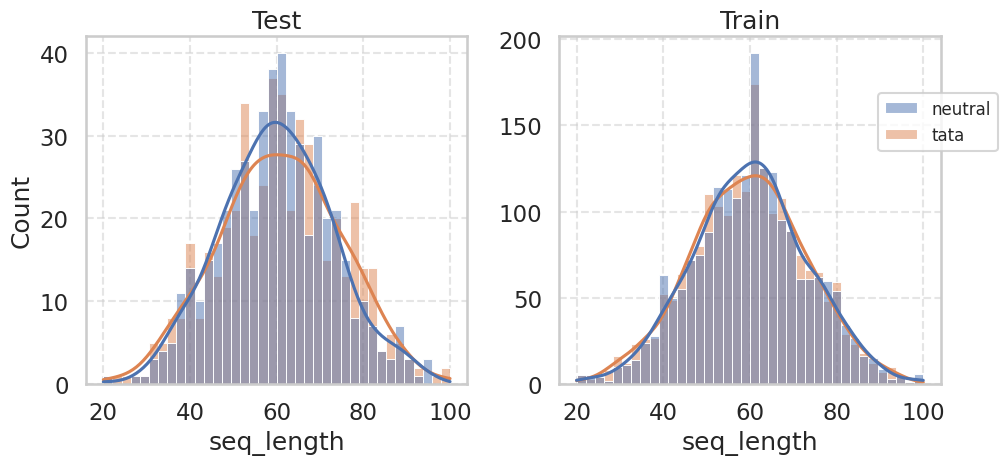

In [4]:
# --- Select style system  ---
sns.set('talk', 'whitegrid')

g = sns.displot(
    data=metadata_df,
    x='seq_length',
    hue='label',
    kde=True,
    col='split',
    facet_kws={'sharey':False},
)

sns.move_legend(
    g,
    "center",
    bbox_to_anchor=(.82, .72),
    frameon=True,
    title=None,
    ncol=1,
    fontsize=12,
)

for ax in g.axes.flat:
    ax.grid(True, linestyle='--', alpha=0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)

g.set_titles('{col_name}')

In [5]:
# --- Model name conversion table ---
model_name_map = {
    'evo2_1b_base':  'Evo2 1B Base',
    'evo2_7b':       'Evo2 7B',
    'evo2_20b':      'Evo2 20B',
    'evo2_40b':      'Evo2 40B',
    'evo2_7b_base':  'Evo2 7B Base',
    'evo2_40b_base': 'Evo2 40B Base',
    'medgemma-1.5-4b-it'  : 'MedGemma 1.5 4B IT',
    'medgemma-27b-text-it': 'MedGemma 27B IT-t',
    'gemma-4-31B-it': 'Gemma 4 31B IT',
}

_EVO2_BASE_RE = re.compile(r"evo2.*base", re.IGNORECASE)
_EVO2_RE      = re.compile(r"evo2", re.IGNORECASE)

def get_model_type(model_name: str) -> str:
    """
    Returns:
        "Evo2"  for any Evo2 instruct/chat model
        "Base"  for any Evo2 base model
        "LLM"   for everything else
    """
    if _EVO2_BASE_RE.search(model_name):
        return "Evo 2 Base"
    if _EVO2_RE.search(model_name):
        return "Evo 2 1M"
    if 'med' in model_name.lower():
        return 'MedGemma'
    return "Gemma 4"

ORDER = [
    'Evo2 7B','Evo2 20B','Evo2 40B',
    'MedGemma 1.5 4B IT', 'MedGemma 27B IT-t', 'Gemma 4 31B IT',
]

In [6]:
for folder in tqdm(os.listdir(results_dir)):
    folder_path = os.path.join(results_dir, folder)
    if not os.path.isdir(folder_path):
        continue
    if 'DEP' in folder_path:
        continue

    # Parse model name and n-shots from folder name e.g. evo2_7b_3shot
    try:
        n_shot = int(folder.split('_')[-1].replace('shot', ''))
        model  = '_'.join(folder.split('_')[:-1])  # everything before _Nshot
        display_model = model_name_map.get(model, model)
    except ValueError:
        print(f"  Skipping unrecognised folder: {folder}")
        continue

    # --- metrics.tsv ---
    metrics_path = os.path.join(folder_path, 'metrics.tsv')
    if os.path.exists(metrics_path):
        df = pd.read_csv(metrics_path, sep='\t')
        for _, row in df.iterrows():
            metrics_rows.append({
                'model':  display_model,
                'type': get_model_type(model),
                'N':      n_shot,
                'metric': row['class'],
                'score':  row['precision'] if 'precision' in row else None,
            })
        # Melt to long format: one row per (model, N, class, metric_type)
        df_melted = df.melt(
            id_vars=['class'],
            value_vars=[c for c in df.columns if c not in ('class', 'support')],
            var_name='metric_type',
            value_name='score'
        )
        for _, row in df_melted.iterrows():
            metrics_rows.append({
                'model':  display_model,
                'type': get_model_type(model),
                'N':      n_shot,
                'metric': f"{row['class']}_{row['metric_type']}",
                'score':  row['score'],
            })

    # --- predictions.tsv ---
    predictions_path = os.path.join(folder_path, 'predictions.tsv')
    if os.path.exists(predictions_path):
        df = pd.read_csv(predictions_path, sep='\t')
        df['model']      = display_model
        df['type']       = get_model_type(model)
        df['N']          = n_shot
        df['seq_length'] =  [test_metadata.loc[test_metadata['seq_id'] == seq_id,'seq_length'].iloc[0] for seq_id in df['seq_id']]
        predictions_rows.append(df)


100%|███████████████████████████████████████████| 49/49 [00:08<00:00,  5.99it/s]


In [7]:
# --- Build final dataframes ---
metrics_df = (
    pd.DataFrame(metrics_rows)
    .drop_duplicates()
    .sort_values(['model', 'N', 'metric'])
    .reset_index(drop=True)
)

predictions_df = (
    pd.concat(predictions_rows, ignore_index=True)
    .sort_values(['model', 'N', 'seq_id', 'seq_length'])
    .reset_index(drop=True)
) if predictions_rows else pd.DataFrame()

In [8]:
predictions_df.sample(2)

,seq_id,true_label,true_class,pred_label,pred_class,correct,nll_class0,nll_class1,ppl_class0,ppl_class1,buffer_nuc,label_nuc_0,label_nuc_1,model,type,N,seq_length
25182,seq_1379,neutral,1,neutral,1,True,8.250000,5.43750,3827.625821,229.866798,A,C,G,Gemma 4 31B IT,Gemma 4,4,69
23111,seq_1227,tata,0,tata,0,True,3.703125,4.84375,40.573900,126.944502,A,T,G,Gemma 4 31B IT,Gemma 4,1,75


In [9]:
if save_dfs:
    # --- Save ---
    metrics_df.to_csv('all_metrics.tsv',     sep='\t', index=False)
    predictions_df.to_csv('all_predictions.tsv', sep='\t', index=False)
    print("\nSaved all_metrics.tsv and all_predictions.tsv")

# Results analysis

Saved lineplot_macro_metrics.png


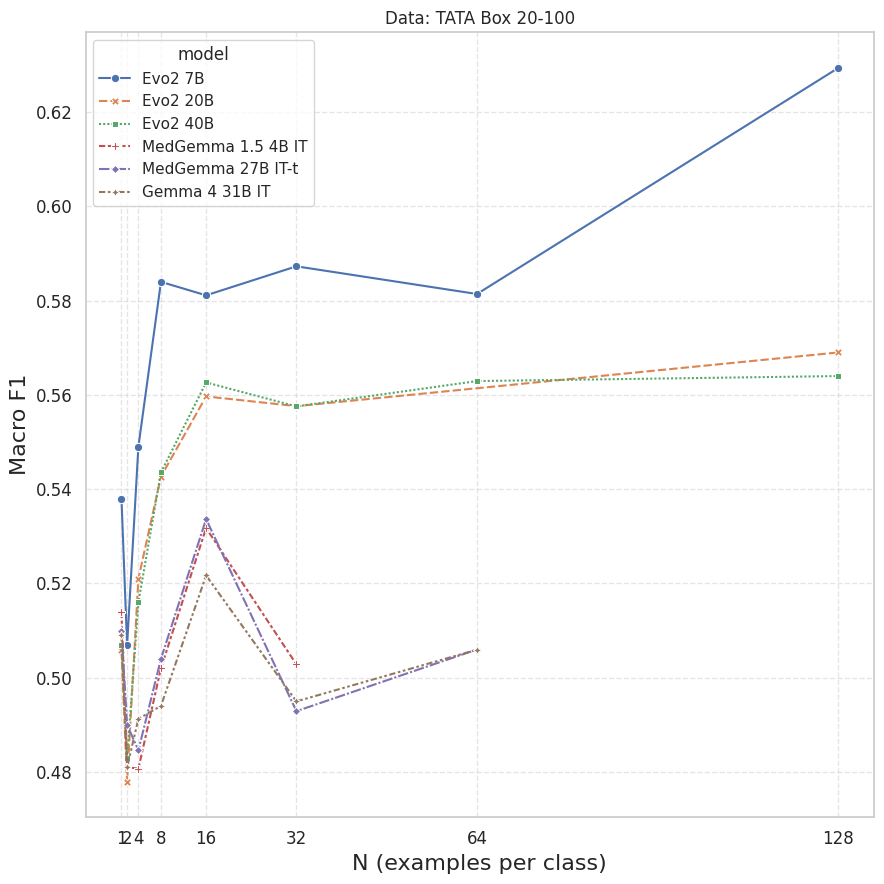

In [10]:
import re
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# --- Select style system  ---
sns.set('notebook', 'whitegrid')

tick_fontsize  = 12
label_fontsize = 16

# --- Select metric weighting system  ---
av = 'macro'

# --- Recompute macro metrics from predictions ---
rows = []
for (model, typ,  n_shot), subset in predictions_df.groupby(['model', 'type', 'N']):
    precision, recall, f1, _ = precision_recall_fscore_support(
        subset['true_label'],
        subset['pred_label'],
        average=av,
        zero_division=0
    )
    accuracy = accuracy_score(subset['true_label'], subset['pred_label'])
    rows.append({'model': model, 'type': typ, 'N': n_shot, 'Metric': 'F1', 'score': f1})
    # rows.append({'model': display_model, 'N': n_shot, 'Metric': 'Accuracy', 'score': accuracy})
    # rows.append({'model': display_model, 'N': n_shot, 'Metric': 'precision','score': precision})
    # rows.append({'model': display_model, 'N': n_shot, 'Metric': 'recall',   'score': recall})

plot_df = pd.DataFrame(rows).sort_values(['model', 'N'])
plot_df = plot_df[plot_df.type != 'Evo 2 Base']

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 9))
sns.lineplot(
    data=plot_df,
    x='N',
    y='score',
    hue='model',
    style='model',
    # palette='Paired',
    hue_order=ORDER,
    style_order=ORDER,
    markers=True,
    dashes=True,
    ax=ax,
    # legend=None
)
ax.set_title(f'Data: {Dir2Title_cnvtb[DATA_dir]}')
ax.set_xlabel('N (examples per class)', fontsize=label_fontsize)
ax.set_ylabel('Macro F1', fontsize=label_fontsize)
ax.tick_params(axis='both', labelsize=tick_fontsize)
ax.set_xticks(sorted(plot_df['N'].unique()))
#ax.set(xlim=(0,32), ylim=(.47, .87))
#ax.legend(title=None, bbox_to_anchor=(0.5, .75), loc='upper left', fontsize=tick_fontsize)

ax.grid(True, linestyle='--', alpha=0.5)

for spine in ax.spines.values():
    spine.set_visible(True)

plt.tight_layout()

if save_fig:
    plt.savefig(f'images/evo2_icl_lineplot_{av}_metrics_{DATA_dir}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'{img_fldr}/evo2_icl_lineplot_{av}_metrics_{DATA_dir}.png', dpi=150, bbox_inches='tight')
    print("Saved lineplot_macro_metrics.png")

plt.show()

Saved ppl_lineplot_by_N_model.png


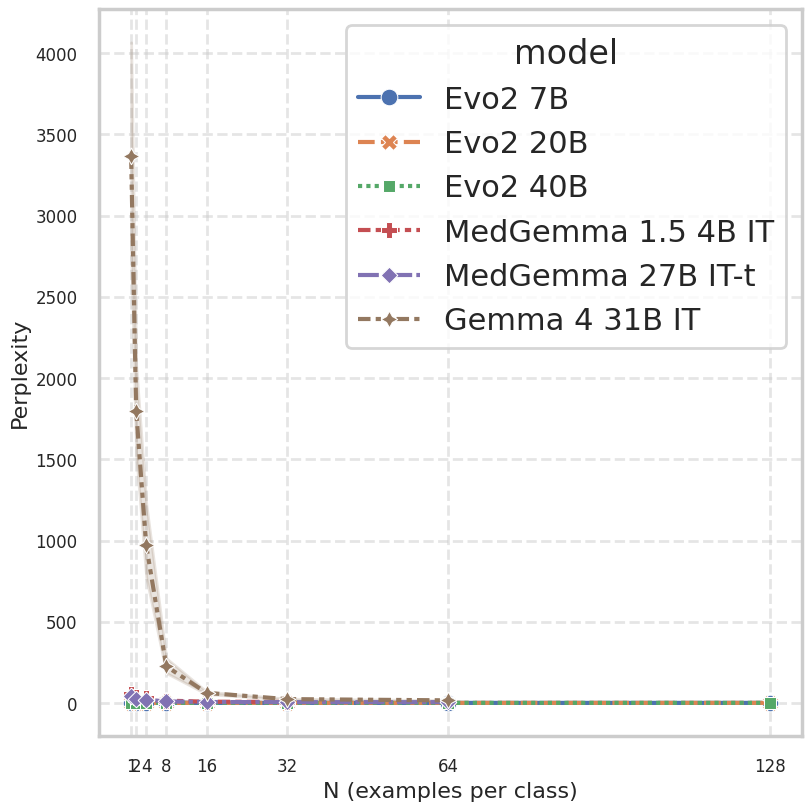

In [11]:
# --- Select style system  ---
sns.set('poster', 'whitegrid')

# --- Settings ---
tick_fontsize  = 12
label_fontsize = 16

# --- Prep ---
df = predictions_df.copy()

# --- Melt ---
df_long = df.melt(
    id_vars=['seq_id', 'type','true_label', 'N', 'model'],
    value_vars=['ppl_class0', 'ppl_class1'],
    var_name='scored_class',
    value_name='perplexity'
).replace({'ppl_class0': 'Class 0', 'ppl_class1': 'Class 1'})
df_long = df_long[df_long.type != 'Evo 2 Base']
# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)

sns.lineplot(
    data=df_long,
    x='N',
    y='perplexity',
    hue='model',
    hue_order=ORDER,
    style='model',
    style_order=ORDER,
    # palette='Paired',
    markers=True,
    dashes=True,
    errorbar='ci',
    ax=ax,
#    legend=None,
)

ax.set_xlabel('N (examples per class)', fontsize=label_fontsize)
ax.set_ylabel('Perplexity', fontsize=label_fontsize)
ax.tick_params(axis='both', labelsize=tick_fontsize)
ax.set_xticks(sorted(df_long['N'].unique()))
# ax.set(xlim=(0, 32), ylim=(1.09,1.97))
ax.grid(True, linestyle='--', alpha=0.5)

for spine in ax.spines.values():
    spine.set_visible(True)

if save_fig:
    fig.savefig('images/ppl_lineplot_by_N_model.png', dpi=150, bbox_inches='tight')
    print("Saved ppl_lineplot_by_N_model.png")

plt.show()

Saved in eos at: f'/eos/jeodpp/data/projects/DIGLIFE/bertolo/images/evo2_icl_relplot_f1_tata.png


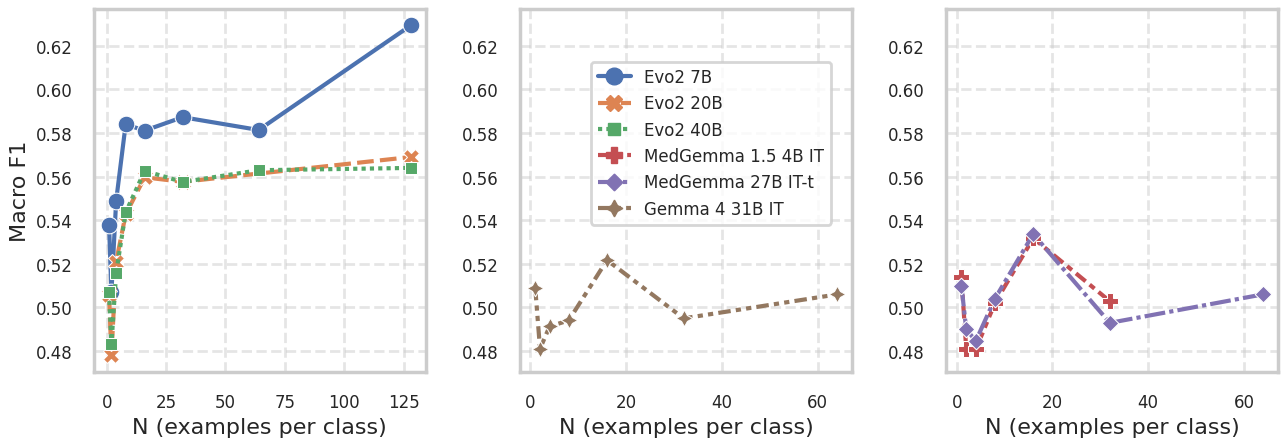

In [14]:
# --- Select style system  ---
sns.set('poster', 'whitegrid')

g = sns.relplot(
    data=plot_df,
    x='N',
    y='score',
    hue='model',
    style='model',
    # palette='Set2',
    hue_order=ORDER,
    style_order=ORDER,
    markers=True,
    dashes=True,
    kind='line',
    col='type',
    facet_kws={'sharex':False, 'sharey':True},
    height=5,      # height of each subplot in inches
    aspect=.6,     # width = height → square
)

sns.move_legend(
    g,
    "center",
    bbox_to_anchor=(.55, .66),
    frameon=True,
    title=None,
    ncol=1,
    fontsize=12,
)
g.set_titles("")
# g.fig.suptitle(f'{av.title()} F1 / Precision / Recall by Model and N-shot', fontsize=13, fontweight='bold')

for ax in g.axes.flat:
    ax.grid(True, linestyle='--', alpha=0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.xaxis.label.set_fontsize(label_fontsize)
    ax.xaxis.set_label_text('N (examples per class)')
    ax.yaxis.label.set_fontsize(label_fontsize)

    # ✅ Force y-tick labels to show on every subplot
    ax.yaxis.set_tick_params(labelleft=True)
    ax.tick_params(axis='y', labelleft=True)
    
g.set_ylabels('Macro F1')
plt.tight_layout()

if save_fig:
    plt.savefig(f'images/evo2_icl_relplot_{av}_metrics.png', dpi=150, bbox_inches='tight')
    plt.savefig(f'{img_fldr}evo2_icl_relplot_f1_{Dir2Lbl_cnvtb[DATA_dir]}.png', dpi=150, bbox_inches='tight')
    print(f"Saved in eos at: f'{img_fldr}evo2_icl_relplot_f1_{Dir2Lbl_cnvtb[DATA_dir]}.png")

plt.show()

Saved in eos at: f'/eos/jeodpp/data/projects/DIGLIFE/bertolo/images/evo2_icl_relplot_ppl_tata.png


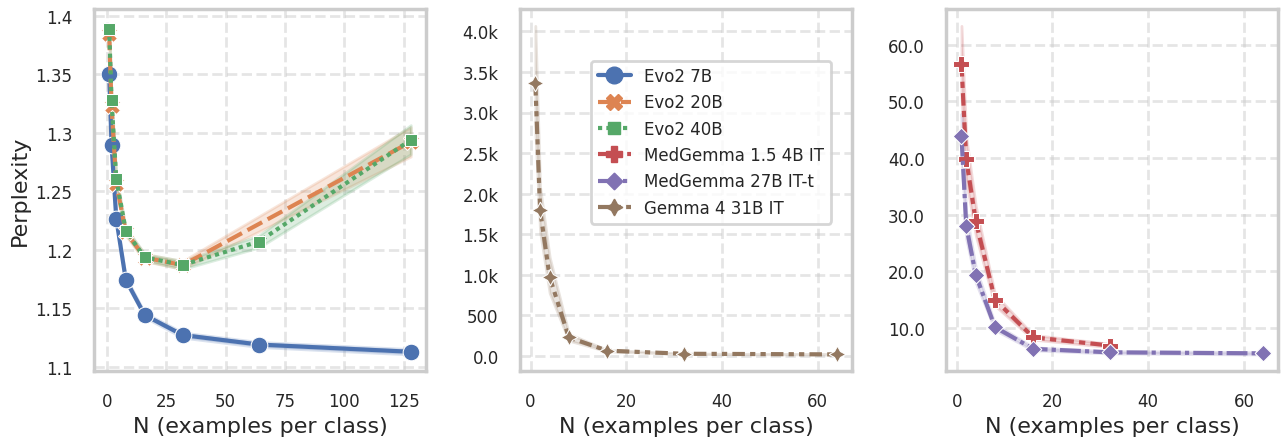

In [13]:
from matplotlib.ticker import FuncFormatter

def fmt_3sig(x, _):
    if abs(x) >= 1_000_000:
        v = x / 1_000_000
        suffix = 'M'
    elif abs(x) >= 1000:
        v = x / 1000
        suffix = 'k'
    else:
        v = x
        suffix = ''
    precision = 2 if suffix else 3
    s = f'{v:.{precision}g}'
    # only add .0 if it's a small number that needs it for consistency
    if '.' not in s and abs(v) < 100:
        s += '.0'
    return s + suffix
    
y_formatter = FuncFormatter(fmt_3sig)

# --- Select style system  ---
sns.set('poster', 'whitegrid')
g = sns.relplot(
    data=df_long,
    x='N',
    y='perplexity',
    hue='model',
    style='model',
    hue_order=ORDER,
    style_order=ORDER,
    markers=True,
    dashes=True,
    kind='line',
    col='type',
    facet_kws={'sharex':False, 'sharey':False},
    height=5,
    aspect=.6,
)
sns.move_legend(
    g,
    "center",
    bbox_to_anchor=(.55, .66),
    frameon=True,
    title=None,
    ncol=1,
    fontsize=12,
)
g.set_titles("")
for ax in g.axes.flat:
    ax.grid(True, linestyle='--', alpha=0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.xaxis.label.set_fontsize(label_fontsize)
    ax.xaxis.set_label_text('N (examples per class)')
    ax.yaxis.set_label_text(None)
    ax.yaxis.label.set_fontsize(label_fontsize)
    ax.yaxis.set_major_formatter(y_formatter)  # ✅ max 3 digits, k/M suffix
g.set_ylabels('Perplexity')
plt.tight_layout()

if save_fig:
    plt.savefig(f'images/ppl_relplot_by_N_model.png', dpi=150, bbox_inches='tight')
    plt.savefig(f'{img_fldr}evo2_icl_relplot_ppl_{Dir2Lbl_cnvtb[DATA_dir]}.png', dpi=150, bbox_inches='tight')
    print(f"Saved in eos at: f'{img_fldr}evo2_icl_relplot_ppl_{Dir2Lbl_cnvtb[DATA_dir]}.png")
plt.show()

Saved ppl_boxplot_by_N_model.png


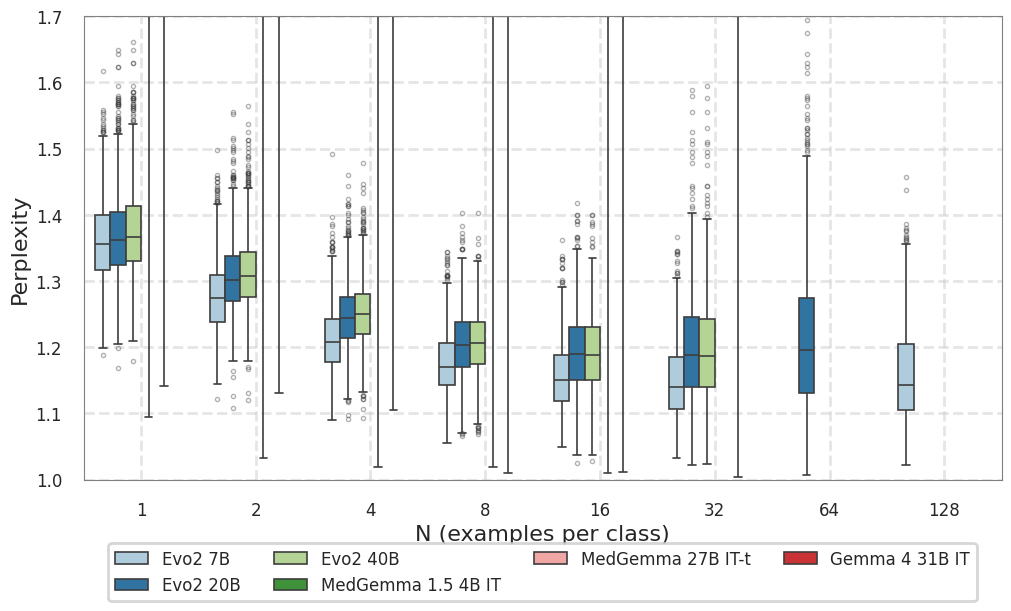

In [14]:
# --- Select style system  ---
sns.set('poster', 'whitegrid')

# --- Settings ---
tick_fontsize  = 12
label_fontsize = 16

# --- Prep ---
df = predictions_df.copy()
df['model_display'] = df['model'].map(lambda x: model_name_map.get(x, x))

# --- Melt ---
df_long = df.melt(
    id_vars=['seq_id', 'true_label', 'N', 'model_display'],
    value_vars=['ppl_class0', 'ppl_class1'],
    var_name='scored_class',
    value_name='perplexity'
).replace({'ppl_class0': 'Class 0', 'ppl_class1': 'Class 1'})

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

sns.boxplot(
    data=df_long,
    x='N',
    y='perplexity',
    hue='model_display',
    hue_order=ORDER,
    palette='Paired',
    linewidth=1.2,
    flierprops=dict(marker='o', markersize=3, alpha=0.4),
    ax=ax,
)

ax.set_xlabel('N (examples per class)', fontsize=label_fontsize)
ax.set_ylabel('Perplexity', fontsize=label_fontsize)
ax.tick_params(axis='both', labelsize=tick_fontsize)
ax.set_ylim(1, 1.7)
ax.grid(True, linestyle='--', alpha=0.5)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('gray')
    spine.set_linewidth(0.8)

sns.move_legend(ax, 'center', bbox_to_anchor=(.5, -0.2),
                frameon=True, title=None, ncol=4,
                fontsize=tick_fontsize)

if save_fig:
    fig.savefig('images/ppl_boxplot_by_N_model.png', dpi=150, bbox_inches='tight')
    print("Saved ppl_boxplot_by_N_model.png")

plt.show()

In [15]:
from sklearn.metrics import roc_curve, auc, precision_recall_fscore_support
import numpy as np4rv4

def plot_auroc(model, n, predictions_df, pos_label='mrna',
               tick_fontsize=12, label_fontsize=16,
               show_operating_point=True,
               save_fig=False, save_path=None):
    sns.set_theme(style='whitegrid', context='poster')

    subset = predictions_df[
        (predictions_df['model'] == model) &
        (predictions_df['N'] == n)
    ].copy()
    if subset.empty:
        raise ValueError(f"No data found for model='{model}', N={n}")

    # --- Bug 1 fix: derive probabilities from NLL, not PPL ---
    # PPL = e^NLL, so applying softmax to PPL would be softmax(e^NLL), which is
    # wrong. We want softmax over log-space scores, i.e. softmax(-NLL), which
    # is equivalent to: prob_i = exp(-nll_i) / sum(exp(-nll_j)).
    # Lower NLL → higher probability → correct class is more likely.
    nll_scores = subset[['nll_class0', 'nll_class1']].values.astype(float)
    log_probs   = -nll_scores                                           # (N, 2)
    log_probs  -= log_probs.max(axis=1, keepdims=True)                  # numerical stability
    probs       = np.exp(log_probs)
    probs      /= probs.sum(axis=1, keepdims=True)                      # proper probabilities

    # --- Bug 2 fix: pos_label must match the dtype of y_true ---
    # true_class is integer (0 = class 0 = 'mrna', 1 = class 1 = 'neutral').
    # We pass pos_label=0 or pos_label=1 to match, instead of a string.
    CLASS_NAMES = [pos_label, 'neutral']   # must match script definition
    pos_class_idx = CLASS_NAMES.index(pos_label)   # 0 or 1
    prob_pos      = probs[:, pos_class_idx]         # score for the positive class

    fpr, tpr, thresholds = roc_curve(
        subset['true_class'].astype(int),
        prob_pos,
        pos_label=pos_class_idx,   # integer, consistent with true_class dtype
    )
    auc_score = auc(fpr, tpr)

    # --- Bug 4 fix: explicit int cast for classification metrics ---
    precision, recall, f1, _ = precision_recall_fscore_support(
        subset['true_class'].astype(int),
        subset['pred_class'].astype(int),
        average='macro',
        zero_division=0,
    )

    display_model = model_name_map.get(model, model)

    fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
    sns.despine(ax=ax, top=True, right=True, left=False, bottom=False)
    sns.lineplot(x=fpr, y=tpr, ax=ax, lw=2,
                 label=f'AUC = {auc_score:.3f}', color='g')
    sns.lineplot(x=[0, 1], y=[0, 1], ax=ax, linestyle='--', lw=1.5,
                 color='grey', label='Random')

    # --- Bug 3 fix: operating point = closest point to top-left corner ---
    # thresholds from roc_curve are score values, not uniform in [0,1], so
    # searching for threshold ≈ 0.5 is meaningless. The standard operating
    # point minimises the Euclidean distance to the ideal (FPR=0, TPR=1).
    op_fpr, op_tpr, op_thr = None, None, None
    if show_operating_point:
        op_idx = np.argmin(np.sqrt(fpr ** 2 + (1 - tpr) ** 2))
        op_fpr = fpr[op_idx]
        op_tpr = tpr[op_idx]
        op_thr = thresholds[op_idx]
        ax.scatter(op_fpr, op_tpr, s=120, zorder=5,
                   label=f'Operating point (thr={op_thr:.2f})')
        ax.annotate(f'FPR={op_fpr:.2f}\nTPR={op_tpr:.2f}',
                    xy=(op_fpr, op_tpr),
                    xytext=(op_fpr + 0.05, op_tpr - 0.1),
                    fontsize=tick_fontsize - 2,
                    arrowprops=dict(arrowstyle='->', color='black'))

    ax.set_xlabel('False Positive Rate', fontsize=label_fontsize)
    ax.set_ylabel('True Positive Rate', fontsize=label_fontsize)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.set_title(f'{display_model}, N={n} | Macro F1={f1:.3f}',
                 fontsize=label_fontsize, fontweight='bold')
    ax.legend(fontsize=label_fontsize - 2, frameon=True)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.01])
    for spine in ax.spines.values():
        spine.set_visible(True)

    if save_fig:
        path = save_path or f'images/auroc_{model}_N{n}.png'
        fig.savefig(path, dpi=150, bbox_inches='tight')
        print(f"Saved {path}")

    plt.show()

    return {
        'fpr': fpr, 'tpr': tpr, 'thresholds': thresholds, 'auc': auc_score,
        'op_fpr': op_fpr, 'op_tpr': op_tpr, 'op_threshold': op_thr,
        'f1': f1, 'precision': precision, 'recall': recall,
    }

In [121]:
auroc_mdl, auroc_N = 'Evo2 7B', 128
results = plot_auroc(
    auroc_mdl,
    auroc_N,
    predictions_df,
    pos_label=Dir2Lbl_cnvtb[DATA_dir],
    save_fig=True,
    show_operating_point=False,
    save_path= f'{img_fldr}_{auroc_N}_auroc_{DATA_dir}.png'
)

NameError: name 'np' is not defined

In [ ]:
auroc_mdl, auroc_N = 'Evo2 40B', 128
results = plot_auroc(
    auroc_mdl,
    auroc_N,
    predictions_df, 
    pos_label=Dir2Lbl_cnvtb[DATA_dir],
    save_fig=True,
    show_operating_point=False,
    save_path= f'images/{auroc_mdl}_{auroc_N}_auroc_{DATA_dir}.png'
)

In [ ]:
try:
    auroc_mdl, auroc_N = 'evo2_1b_base', 8
    results = plot_auroc(
        auroc_mdl,
        auroc_N,
        predictions_df, 
        pos_label=DATA,
        save_fig=True,
        show_operating_point=False,
        save_path= f'images/{auroc_mdl}_{auroc_N}_auroc_{DATA}.png'
    )
except Exception as E:
    print(E)

# Error analysis
## Confusion matrices

Saved images/evo2_icl_confusion_matrices.png


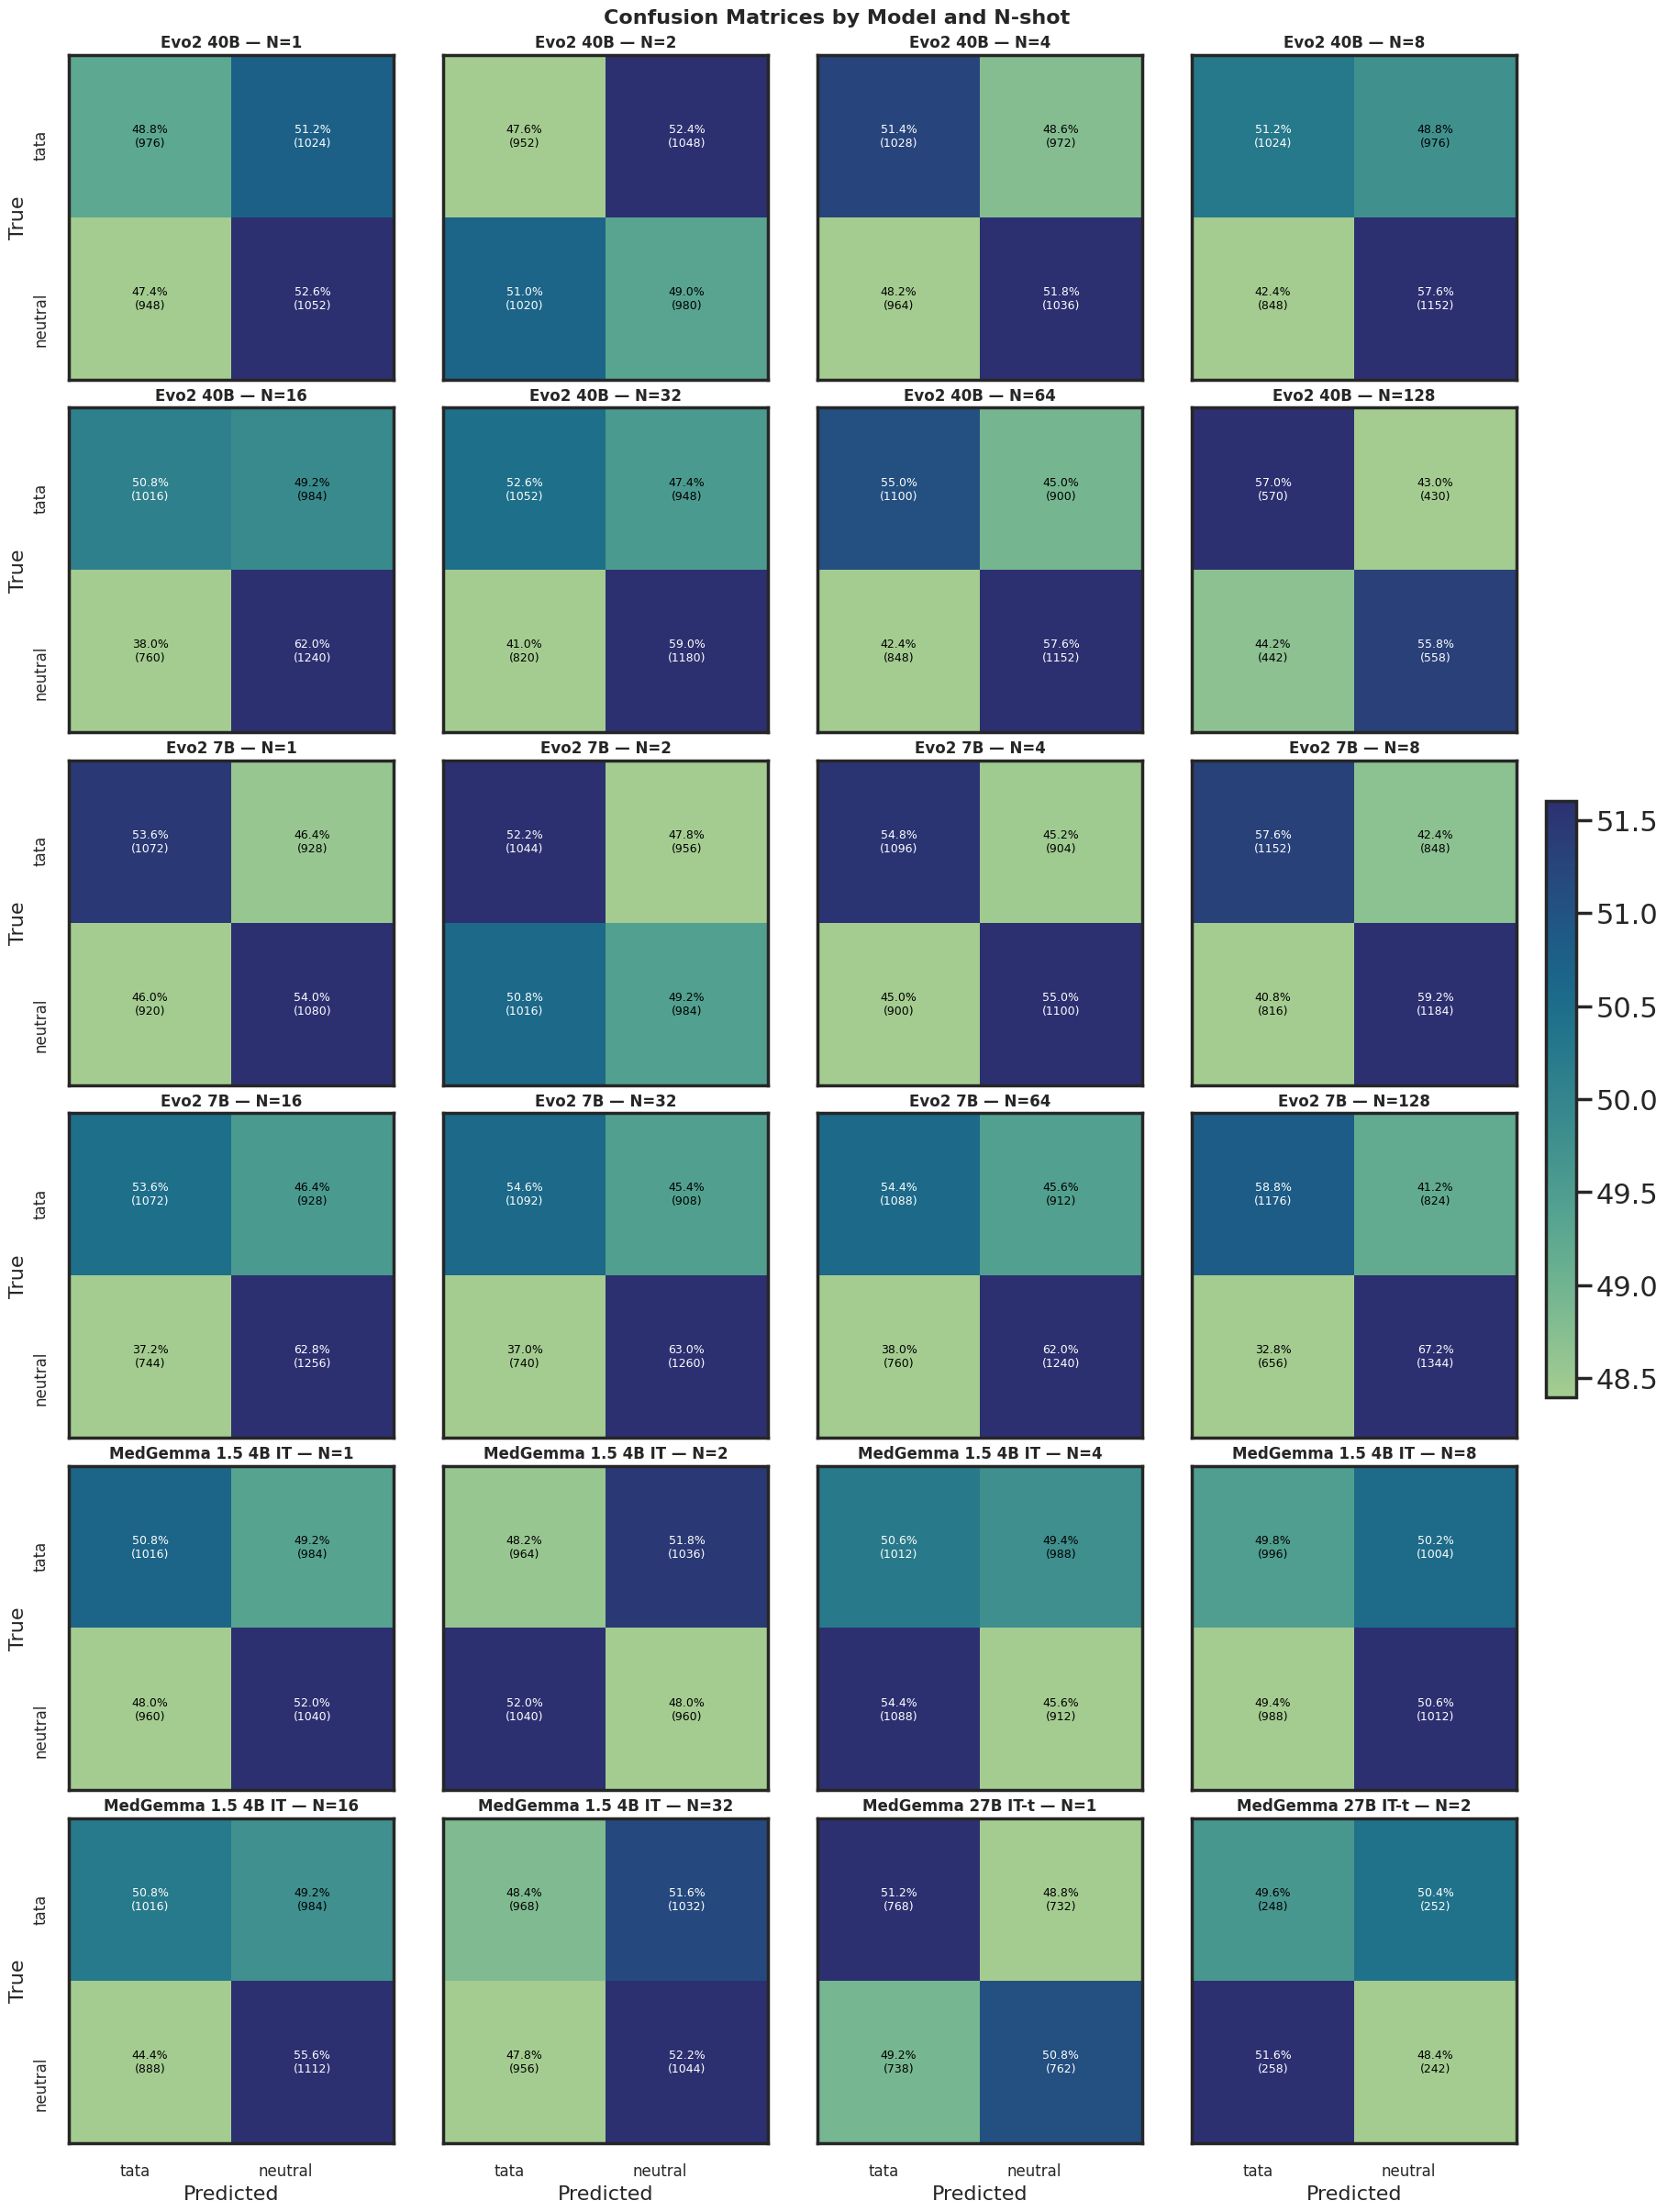

In [124]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

label_names = [Dir2Lbl_cnvtb[DATA_dir], 'neutral']

# --- Select style system  ---
sns.set('poster', 'white')

# --- Get all unique model-N combinations ---
combinations = (
    predictions_df[['model', 'N']]
    .drop_duplicates()
    .sort_values(['model', 'N'])
    .reset_index(drop=True)
)
n_combos = len(combinations)
n_cols   = min(4, n_combos)
n_rows   = (n_combos + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(4.5 * n_cols, 4 * n_rows),
                         constrained_layout=True)
axes = np.array(axes).reshape(-1)
im = None

for idx, (_, row) in enumerate(combinations.iterrows()):
    model  = row['model']
    n_shot = row['N']
    subset = predictions_df[(predictions_df['model'] == model) & (predictions_df['N'] == n_shot)]
    cm     = confusion_matrix(subset['true_label'], subset['pred_label'], labels=label_names)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    ax = axes[idx]
    im = ax.imshow(cm_pct, interpolation='nearest', cmap='crest')  # per-subplot normalization

    is_last_row = (idx // n_cols == n_rows - 1) or (idx == n_combos - 1)
    is_left_col = (idx % n_cols == 0)

    # Y-axis
    ax.set_yticks(range(len(label_names)))
    if is_left_col:
        ax.set_yticklabels(label_names, rotation=90, ha='right', fontsize=12)
        ax.set_ylabel('True', fontsize=16)
    else:
        ax.set_yticklabels([''] * len(label_names))
        ax.tick_params(axis='y', left=False)

    # X-axis
    ax.set_xticks(range(len(label_names)))
    if is_last_row:
        ax.set_xticklabels(label_names, rotation=0, ha='right', fontsize=12)
        ax.set_xlabel('Predicted', fontsize=16)
    else:
        ax.set_xticklabels([''] * len(label_names))
        ax.tick_params(axis='x', bottom=False)

    display_model = model_name_map.get(model, model)
    ax.set_title(f"{display_model} — N={n_shot}", fontsize=12, fontweight='bold')

    for i in range(len(label_names)):
        for j in range(len(label_names)):
            color = 'white' if cm_pct[i, j] > 50 else 'black'
            ax.text(j, i, f"{cm_pct[i, j]:.1f}%\n({cm[i, j]})",
                    ha='center', va='center', fontsize=9, color=color)

# Clean up unused axes
for idx in range(n_combos, len(axes)):
    axes[idx].set_xticks([])
    axes[idx].set_yticks([])
    for spine in axes[idx].spines.values():
        spine.set_visible(False)

# Single shared colorbar
fig.colorbar(im, ax=axes[:n_combos], fraction=0.02, pad=0.02)

plt.suptitle('Confusion Matrices by Model and N-shot', fontsize=16, fontweight='bold')

if save_fig:
    output_path = 'images/evo2_icl_confusion_matrices.png'
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    print(f"Saved {output_path}")

plt.show()

## Correlation analysis: correctness vs sequence length

Saved images/evo2_icl_corrvslen_N_tata_n5000_min20_max100.png


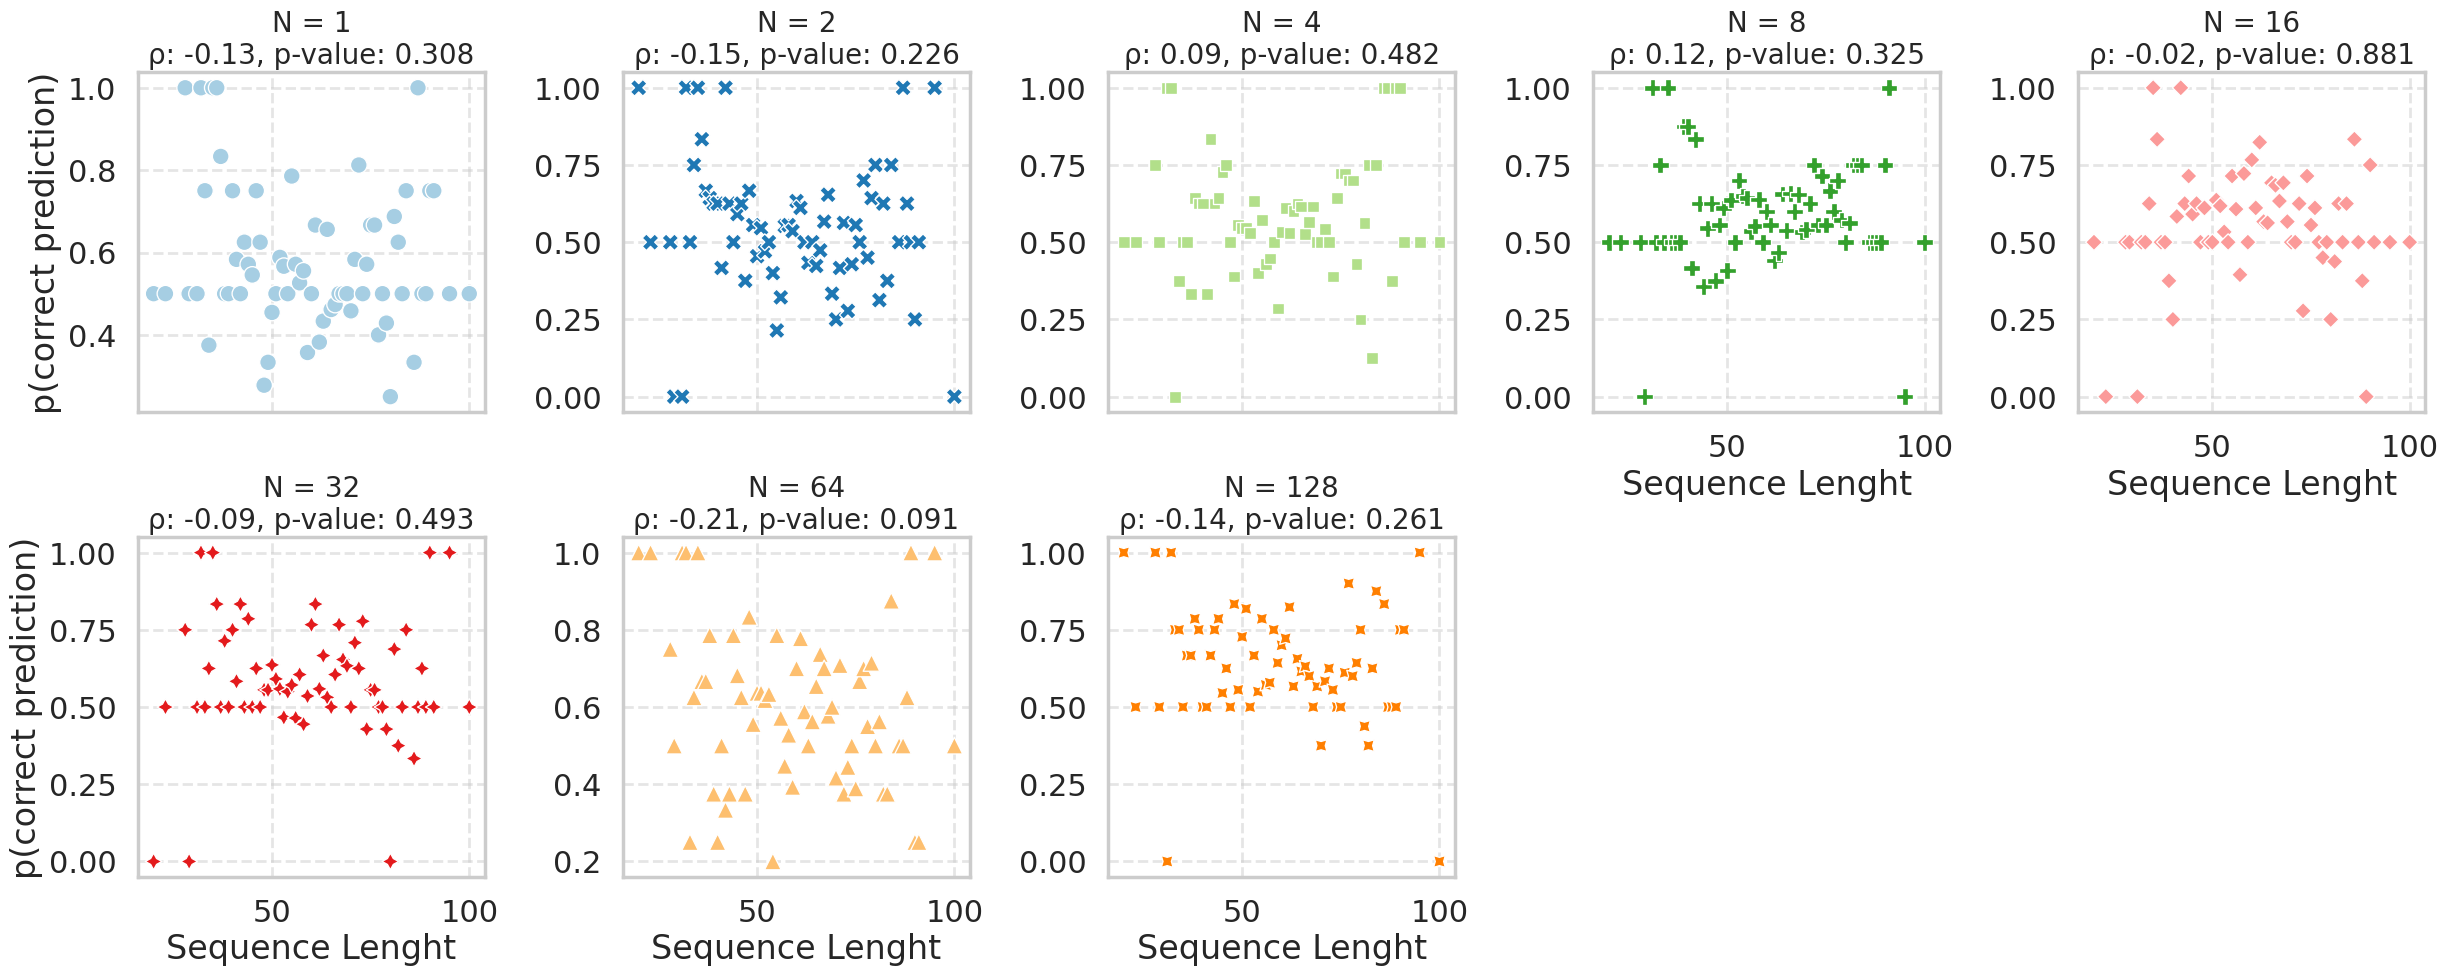

In [123]:
from scipy import stats
import pingouin as pg

correct_p_val = False

# Select style system 
sns.set('poster', 'whitegrid')

# Groups by length and ID only
df_prob_seq = predictions_df[predictions_df['model'] == 'Evo2 7B'].groupby(['seq_length', 'N'])['correct'].mean().reset_index()

# Rename column for clarity
df_prob_seq.rename(columns={'correct': 'prob_correct'}, inplace=True)

# Correlation and p-value
rho, p_value = stats.spearmanr(df_prob_seq['prob_correct'], df_prob_seq['seq_length'])

rho_dict = {}
ps = []

# Correlation and p-value
for n in df_prob_seq['N'].unique():
    df = df_prob_seq[df_prob_seq['N'] == n]
    rho, p_value = stats.spearmanr(df['prob_correct'], df['seq_length'])
    rho_dict[n] = [rho, p_value]
    ps.append(p_value)

reject, pvals_corr = pg.multicomp(ps, method="holm")

if correct_p_val:
    print('Correcting p values')
    for c, (n, vls) in enumerate(rho_dict.items()):
        print(f'N: {n}, rho: {vls[0]:.2f}, p {vls[1]:.3f}, p Holm {pvals_corr[c]:.3f}')
        rho_dict[n][1] = pvals_corr[c]

# Plot the data
g = sns.relplot(
    data=df_prob_seq,
    x='seq_length',
    y='prob_correct',
    hue='N',
    col='N',
    style='N',
    palette='Paired',
    kind='scatter',
    legend=None,
    col_wrap=5,
    facet_kws={'sharey': False},
)

g.set_titles(
    template='',  # clear default
)

for i, (ax, col_val) in enumerate(zip(g.axes.flat, g.col_names)):
    rho = rho_dict[col_val][0]
    pval = rho_dict[col_val][1]
    ax.set_title(f"N = {col_val}\nρ: {rho:.2f}, p-value: {pval:.3f}", fontsize=20)

    ax.grid(True, linestyle='--', alpha=0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)

    if i in [0,5]:
        ax.set(ylabel='p(correct prediction)')
    else:
        ax.set(ylabel='')

g.set(xlabel='Sequence Lenght')

if save_fig:
    output_path = f'images/evo2_icl_corrvslen_N_{DATA_dir}.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.savefig(f'{img_fldr}/evo2_icl_corrvslen_N_{DATA_dir}.png', dpi=150, bbox_inches='tight')
    print(f"Saved {output_path}")

plt.show()

## Error consistency: seuqence ID to N

Saved images/evo2_icl_heatmap_corrvslen_N.png


/scratch/bertolo/conda/brtl_scnv/lib/python3.11/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))
/scratch/bertolo/conda/brtl_scnv/lib/python3.11/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))


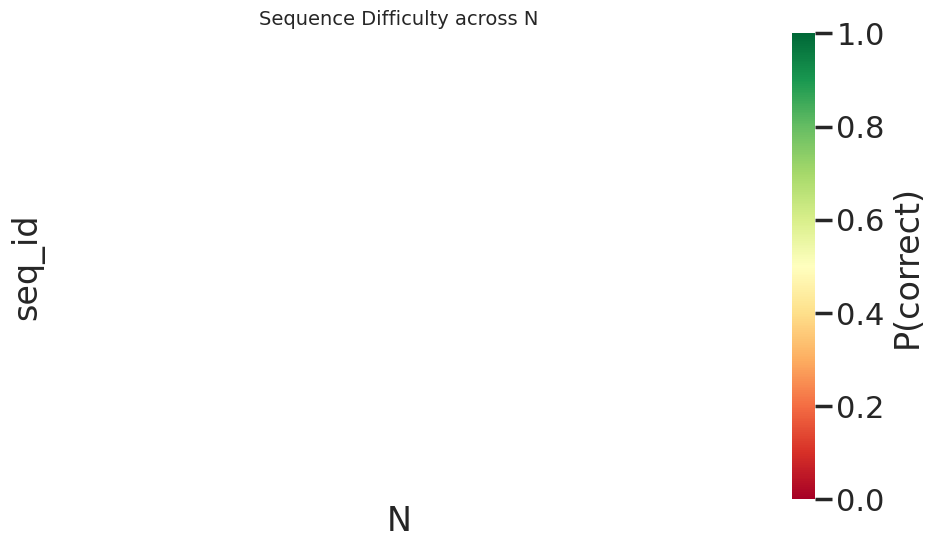

In [31]:
# Aggregate prob correct per seq_id and N
pivot = (
    predictions_df[predictions_df['model'] == 'evo2_7b'].groupby(['seq_id', 'N'])['correct']
    .mean()
    .unstack('N')
)

# Sort by mean prob so hardest sequences appear at top
pivot = pivot.loc[pivot.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, max(6, len(pivot) * 0.3)))
sns.heatmap(
    pivot,
    ax=ax,
    cmap='RdYlGn',
    vmin=0, vmax=1,
    linewidths=0.3,
    cbar_kws={'label': 'P(correct)'}
)
ax.set_title("Sequence Difficulty across N", fontsize=14)
ax.set_xlabel('N')
ax.set_ylabel('seq_id')
plt.tight_layout()
if save_fig:
    output_path = 'images/evo2_icl_heatmap_corrvslen_N.png'
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    print(f"Saved {output_path}")
plt.show()

## Model's Confidnce 